# MES – Exploratory Analysis (1min)

**Period:** Feb–Apr 2026 (In‑Sample)  
**Goal:** Find statistical edges for 1‑day competition

## 0. Check Data

In [1]:
import os
out_dir = "../../../../Local-Data/processed"
print("Generated files:")
for f in sorted(os.listdir(out_dir)):
    print(f"  - {f}")

Generated files:
  - .DS_Store
  - 6E_IS_1min.csv
  - 6E_OOS_ticks.csv
  - MCL_IS_1min.csv
  - MCL_OOS_1min.csv
  - MES_IS_1min.csv
  - MES_OOS_ticks.csv
  - MGC_IS_1min.csv
  - MGC_OOS_1min.csv
  - MNQ_IS_1min.csv
  - MNQ_OOS_ticks.csv


## 1. Setup & load data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")

In [3]:
INSTRUMENT = "MES"
DATA_PATH = "../../../../Local-Data/processed/MES_IS_1min.csv"

df = pd.read_csv(DATA_PATH, parse_dates=['DateTime'], index_col='DateTime')
print(f"Loaded {len(df):,} rows for {INSTRUMENT}")
df.head()

Loaded 87,799 rows for MES


,Open,High,Low,Close,Volume
DateTime,,,,,
2026-02-01 13:52:00,6961.25,6961.25,6961.25,6961.25,1
2026-02-01 20:01:00,6939.50,6945.25,6928.25,6936.75,2717
2026-02-01 20:02:00,6937.25,6937.75,6925.75,6926.75,1939
2026-02-01 20:03:00,6926.50,6927.75,6920.00,6927.00,2748
2026-02-01 20:04:00,6927.00,6931.50,6926.00,6928.75,1374


## 2. Basic Statistics & Returns

In [4]:
df['return'] = df['Close'].pct_change()
df['log_return'] = np.log(df['Close'] / df['Close'].shift(1))
df['abs_return'] = df['return'].abs()
df['volume_zscore'] = (df['Volume'] - df['Volume'].rolling(20).mean()) / df['Volume'].rolling(20).std()

def ATR(high, low, close, period=14):
    tr = pd.concat([high - low, 
                    (high - close.shift()).abs(), 
                    (low - close.shift()).abs()], axis=1).max(axis=1)
    return tr.rolling(period).mean()

df['ATR14'] = ATR(df['High'], df['Low'], df['Close'], 14)

print(f"Mean return (1min): {df['return'].mean()*100:.4f}%")
print(f"Std return (1min): {df['return'].std()*100:.4f}%")
print(f"Mean volume: {df['Volume'].mean():.0f}")


Mean return (1min): 0.0001%
Std return (1min): 0.0310%
Mean volume: 1097


## 3. Autocorrelation

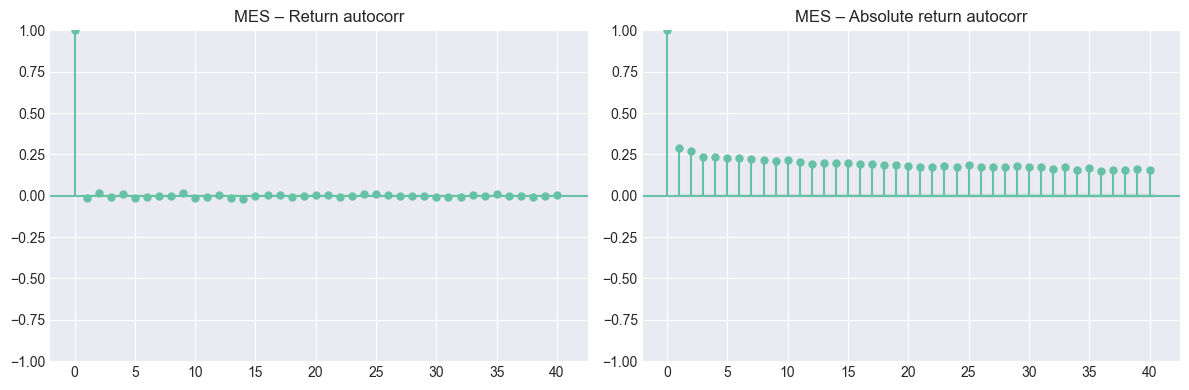


=== 📊 Autocorrelation Interpretation ===
🔹 Return autocorrelation (lag 1): -0.0143
   → No significant lag-1 autocorrelation; returns are nearly independent.
🔹 Absolute return autocorrelation (lag 1): 0.2896
   → Strong volatility clustering: high-volatility periods persist. Useful for dynamic filters and sizing.

🔹 Ljung‑Box test for returns (portmanteau test):
   - p-value at 5 lags: 0.0000
   - p-value at 10 lags: 0.0000
   - p-value at 20 lags: 0.0000
   → Significant temporal structure in returns – exploitable edge possible.


In [6]:

fig, axes = plt.subplots(1, 2, figsize=(12,4))
plot_acf(df['return'].dropna(), lags=40, ax=axes[0], title=f'{INSTRUMENT} – Return autocorr')
plot_acf(df['abs_return'].dropna(), lags=40, ax=axes[1], title=f'{INSTRUMENT} – Absolute return autocorr')
plt.tight_layout()
plt.show()

from statsmodels.stats.diagnostic import acorr_ljungbox

acf_ret = pd.Series(df['return'].dropna()).autocorr(lag=1)
acf_abs = pd.Series(df['abs_return'].dropna()).autocorr(lag=1)

lb = acorr_ljungbox(df['return'].dropna(), lags=[5,10,20], return_df=True)

print("\n=== 📊 Autocorrelation Interpretation ===")
print(f"🔹 Return autocorrelation (lag 1): {acf_ret:.4f}")
if acf_ret > 0.05:
    print("   → Weak momentum effect: positive returns tend to be followed by positive returns (1-min horizon).")
elif acf_ret < -0.05:
    print("   → Weak mean reversion: positive returns tend to be followed by negative returns.")
else:
    print("   → No significant lag-1 autocorrelation; returns are nearly independent.")

print(f"🔹 Absolute return autocorrelation (lag 1): {acf_abs:.4f}")
if acf_abs > 0.10:
    print("   → Strong volatility clustering: high-volatility periods persist. Useful for dynamic filters and sizing.")
else:
    print("   → Low persistence in volatility; market conditions change rapidly.")

print("\n🔹 Ljung‑Box test for returns (portmanteau test):")
print(f"   - p-value at 5 lags: {lb['lb_pvalue'].iloc[0]:.4f}")
print(f"   - p-value at 10 lags: {lb['lb_pvalue'].iloc[1]:.4f}")
print(f"   - p-value at 20 lags: {lb['lb_pvalue'].iloc[2]:.4f}")
if lb['lb_pvalue'].iloc[0] < 0.05:
    print("   → Significant temporal structure in returns – exploitable edge possible.")
else:
    print("   → Cannot reject white noise hypothesis; pure directional edge may be weak.")

## 4. Intraday seasonality

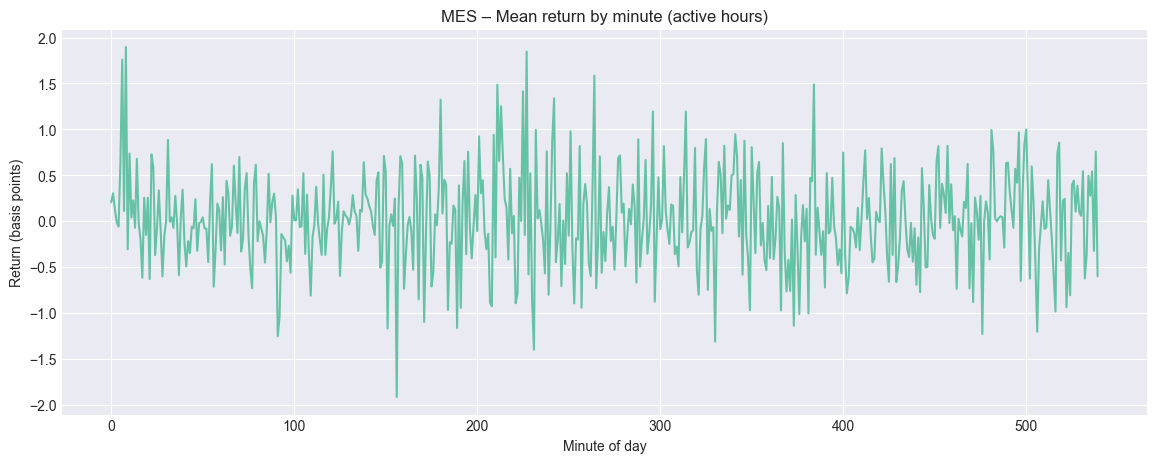

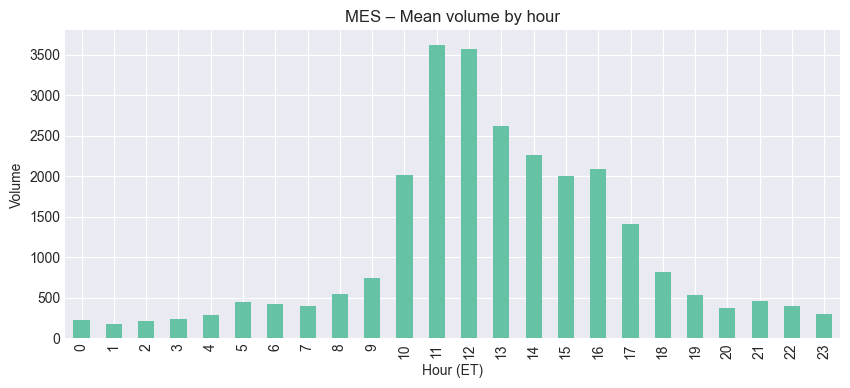


=== ⏰ Intraday Seasonality Interpretation ===
🔹 Hour with highest mean return: 4:00 ET – 0.0010%
🔹 Hour with lowest mean return: 19:00 ET – -0.0012%
🔹 Hour with highest volume: 11:00 ET – 3623 contracts

🔹 Hours with significant mean returns (>0.001% in absolute value):
      14:00 → -0.0011%
      19:00 → -0.0012%

🔹 Volume pattern: Typically highest at market open (liquidity), then declines towards midday, with a slight increase near the close.


In [7]:

df['hour'] = df.index.hour
df['minute'] = df.index.minute
df['time_of_day'] = df.index.strftime('%H:%M')

active_mask = (df['hour'] >= 8) & (df['hour'] <= 16)
intraday_returns = df[active_mask].groupby('time_of_day')['return'].mean()

plt.figure(figsize=(14,5))
plt.plot(range(len(intraday_returns)), intraday_returns.values * 10000)  # in basis points
plt.title(f'{INSTRUMENT} – Mean return by minute (active hours)')
plt.xlabel('Minute of day')
plt.ylabel('Return (basis points)')
plt.grid(True)
plt.show()

hourly_vol = df.groupby('hour')['Volume'].mean()
plt.figure(figsize=(10,4))
hourly_vol.plot(kind='bar')
plt.title(f'{INSTRUMENT} – Mean volume by hour')
plt.xlabel('Hour (ET)')
plt.ylabel('Volume')
plt.show()

hourly_return = df.groupby('hour')['return'].mean()
best_hour_return = hourly_return.idxmax()
worst_hour_return = hourly_return.idxmin()
best_hour_vol = hourly_vol.idxmax()

print("\n=== ⏰ Intraday Seasonality Interpretation ===")
print(f"🔹 Hour with highest mean return: {best_hour_return}:00 ET – {hourly_return[best_hour_return]*100:.4f}%")
print(f"🔹 Hour with lowest mean return: {worst_hour_return}:00 ET – {hourly_return[worst_hour_return]*100:.4f}%")
print(f"🔹 Hour with highest volume: {best_hour_vol}:00 ET – {hourly_vol[best_hour_vol]:.0f} contracts")

significant_hours = hourly_return[abs(hourly_return) > 0.00001].sort_values(ascending=False)
if not significant_hours.empty:
    print("\n🔹 Hours with significant mean returns (>0.001% in absolute value):")
    for h, val in significant_hours.head(5).items():
        print(f"      {h}:00 → {val*100:.4f}%")
else:
    print("\n🔹 No hours with significant mean returns (all near zero).")

print("\n🔹 Volume pattern: Typically highest at market open (liquidity), then declines towards midday, with a slight increase near the close.")

## 5. Gap behaviour

Gap analysis (mean forward return):
          return_5m  return_10m  return_20m  count
gap_sign                                          
-1         0.000256    0.000228    0.000329     17
 0         0.000003    0.000006    0.000012  87767
 1         0.000606    0.000729    0.000728     14


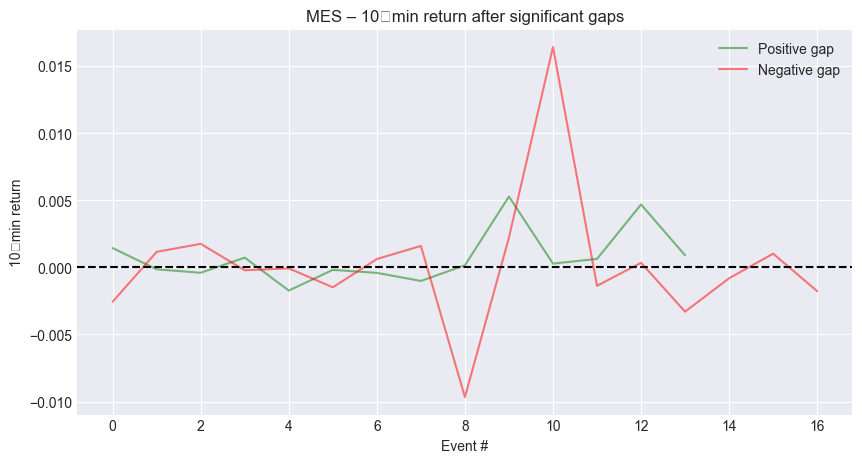


=== 📈 Gap Analysis Interpretation ===
🔹 Positive gaps (>0.05%): 14.0 occurrences.
   Mean return after 5 min:  0.0606%
   Mean return after 10 min: 0.0729%
   Mean return after 20 min: 0.0728%
   → Positive gaps tend to CONTINUE upward (gap momentum).

🔹 Negative gaps (< -0.05%): 17.0 occurrences.
   Mean return after 5 min:  0.0256%
   Mean return after 10 min: 0.0228%
   Mean return after 20 min: 0.0329%
   → Negative gaps tend to REVERSE upward.

🔹 Recommendation: If reversal exists, fade the gap; if continuation, trade in gap direction. Combine with volume anomaly for higher reliability.


In [8]:

df['gap'] = (df['Open'] - df['Close'].shift(1)) / df['Close'].shift(1)
gap_threshold = 0.0005
df['gap_sign'] = 0
df.loc[df['gap'] > gap_threshold, 'gap_sign'] = 1
df.loc[df['gap'] < -gap_threshold, 'gap_sign'] = -1

for fwd in [5, 10, 20]:
    df[f'return_{fwd}m'] = df['Close'].shift(-fwd) / df['Open'] - 1

gap_analysis = df.groupby('gap_sign').agg({
    'return_5m': 'mean', 'return_10m': 'mean', 'return_20m': 'mean', 'gap': 'count'
}).rename(columns={'gap': 'count'})
print("Gap analysis (mean forward return):")
print(gap_analysis)

# Plot individual 10-min returns after significant gaps
significant_gaps = df[df['gap'].abs() > gap_threshold].copy()
plt.figure(figsize=(10,5))
for sign, color, label in [(1, 'green', 'Positive gap'), (-1, 'red', 'Negative gap')]:
    subset = significant_gaps[significant_gaps['gap_sign'] == sign]
    if len(subset) > 10:
        plt.plot(subset['return_10m'].values, color=color, alpha=0.5, label=label)
plt.axhline(y=0, color='black', linestyle='--')
plt.title(f'{INSTRUMENT} – 10‑min return after significant gaps')
plt.xlabel('Event #')
plt.ylabel('10‑min return')
plt.legend()
plt.show()

# Detailed interpretation
print("\n=== 📈 Gap Analysis Interpretation ===")
pos = gap_analysis.loc[1] if 1 in gap_analysis.index else None
neg = gap_analysis.loc[-1] if -1 in gap_analysis.index else None

if pos is not None:
    print(f"🔹 Positive gaps (>{gap_threshold*100:.2f}%): {pos['count']} occurrences.")
    print(f"   Mean return after 5 min:  {pos['return_5m']*100:.4f}%")
    print(f"   Mean return after 10 min: {pos['return_10m']*100:.4f}%")
    print(f"   Mean return after 20 min: {pos['return_20m']*100:.4f}%")
    if pos['return_10m'] > 0.0001:
        print("   → Positive gaps tend to CONTINUE upward (gap momentum).")
    elif pos['return_10m'] < -0.0001:
        print("   → Positive gaps tend to REVERSE (gap filling).")
    else:
        print("   → No clear bias after positive gaps.")

if neg is not None:
    print(f"\n🔹 Negative gaps (< -{gap_threshold*100:.2f}%): {neg['count']} occurrences.")
    print(f"   Mean return after 5 min:  {neg['return_5m']*100:.4f}%")
    print(f"   Mean return after 10 min: {neg['return_10m']*100:.4f}%")
    print(f"   Mean return after 20 min: {neg['return_20m']*100:.4f}%")
    if neg['return_10m'] < -0.0001:
        print("   → Negative gaps tend to CONTINUE downward.")
    elif neg['return_10m'] > 0.0001:
        print("   → Negative gaps tend to REVERSE upward.")
    else:
        print("   → No clear bias after negative gaps.")

print("\n🔹 Recommendation: If reversal exists, fade the gap; if continuation, trade in gap direction. Combine with volume anomaly for higher reliability.")

## 6. Volume anomalies

In [9]:
df['high_vol'] = df['volume_zscore'] > 1.5
forward_after_highvol = df[df['high_vol']]['return_10m'].describe()
print("10‑min return after high volume:\n", forward_after_highvol)

baseline = df[~df['high_vol']]['return_10m'].mean()
highvol_mean = df[df['high_vol']]['return_10m'].mean()
print(f"Baseline 10‑min return: {baseline*100:.3f}%")
print(f"After high volume:       {highvol_mean*100:.3f}%")

10‑min return after high volume:
 count    7917.000000
mean        0.000036
std         0.001175
min        -0.011038
25%        -0.000434
50%         0.000036
75%         0.000460
max         0.032679
Name: return_10m, dtype: float64
Baseline 10‑min return: 0.000%
After high volume:       0.004%


## 7. Volatility regimes

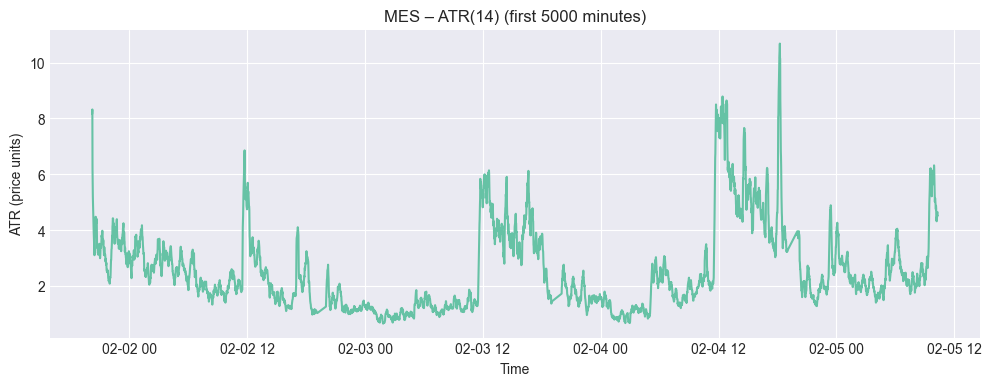

Average 10‑min return by volatility regime:
  Low vol:  -0.00028%
  High vol: 0.00155%

=== ⚡ Volatility Regime Impact ===
🔹 Mean 10‑min return in LOW volatility: -0.00028%
🔹 Mean 10‑min return in HIGH volatility: 0.00155%
   → Performance is 0.00183% HIGHER in high volatility. Prefer trading during high-volatility periods.

🔹 ATR14 30th percentile: 1.464 (low volatility threshold)
🔹 ATR14 70th percentile: 2.929 (high volatility threshold)
Suggestion: Implement a volatility filter – e.g., trade only when ATR14 > 70th percentile if edge is higher there, or vice versa.


In [10]:

plt.figure(figsize=(12,4))
plt.plot(df.index[:5000], df['ATR14'].iloc[:5000])
plt.title(f'{INSTRUMENT} – ATR(14) (first 5000 minutes)')
plt.ylabel('ATR (price units)')
plt.xlabel('Time')
plt.show()

median_atr = df['ATR14'].median()
df['high_volatility'] = df['ATR14'] > median_atr
vol_regime_ret = df.groupby('high_volatility')['return_10m'].mean()
print("Average 10‑min return by volatility regime:")
print(f"  Low vol:  {vol_regime_ret[False]*100:.5f}%")
print(f"  High vol: {vol_regime_ret[True]*100:.5f}%")

# Additional analysis
print("\n=== ⚡ Volatility Regime Impact ===")
low_ret = vol_regime_ret[False]
high_ret = vol_regime_ret[True]
print(f"🔹 Mean 10‑min return in LOW volatility: {low_ret*100:.5f}%")
print(f"🔹 Mean 10‑min return in HIGH volatility: {high_ret*100:.5f}%")

if high_ret > low_ret:
    diff = (high_ret - low_ret)*100
    print(f"   → Performance is {diff:.5f}% HIGHER in high volatility. Prefer trading during high-volatility periods.")
elif high_ret < low_ret:
    diff = (low_ret - high_ret)*100
    print(f"   → Performance is {diff:.5f}% LOWER in high volatility. Reduce position size or avoid high-volatility regimes.")
else:
    print("   → No significant difference between volatility regimes.")

# Percentiles for practical filters
atr_p30 = df['ATR14'].quantile(0.30)
atr_p70 = df['ATR14'].quantile(0.70)
print(f"\n🔹 ATR14 30th percentile: {atr_p30:.3f} (low volatility threshold)")
print(f"🔹 ATR14 70th percentile: {atr_p70:.3f} (high volatility threshold)")
print("Suggestion: Implement a volatility filter – e.g., trade only when ATR14 > 70th percentile if edge is higher there, or vice versa.")

## 8. Summary table

In [26]:
summary = {
    'Instrument': INSTRUMENT,
    'Rows': len(df),
    'Mean return (1m) %': df['return'].mean() * 100,
    'Std return (1m) %': df['return'].std() * 100,
    'Mean volume': df['Volume'].mean(),
    'Mean ATR14': df['ATR14'].mean(),
    'Gap freq (>0.05%) %': (df['gap'].abs() > 0.0005).mean() * 100,
    'Mean 10m return after gap >0.05%': df[df['gap'].abs() > 0.0005]['return_10m'].mean(),
    'Mean 10m return after high vol': df[df['high_vol']]['return_10m'].mean(),
}
pd.DataFrame([summary]).T

,0
Instrument,MES
Rows,87799
Mean return (1m) %,0.000051
Std return (1m) %,0.03101
Mean volume,1096.809531
Mean ATR14,2.508687
Gap freq (>0.05%) %,0.035308
Mean 10m return after gap >0.05%,0.000454
Mean 10m return after high vol,0.000036
